In [1]:
import sys
sys.path.insert(0, "..")  # repository root, so `import km5c` works
from km5c.paths import FIG_DIR
import matplotlib.colors as mcolors
import numpy as np
import numpy.ma as ma
import pandas as pd

from km5c.plotting import equatorplot, latdepthplot, shade_below_bathymetry
from km5c.transects import extract_transect_section_lon_band_mean, project_points_to_transect
from km5c.models import load_cesm122
from km5c.proxies import comparison_tables

cesm122 = load_cesm122()
cesm122_Plio_d13C = cesm122.Plio_d13C
cesm122_Plio_depth = cesm122.Plio_depth
cesm122_Plio_lat = cesm122.Plio_lat
cesm122_Plio_lon = cesm122.Plio_lon

proxy = comparison_tables()
PLIOMIP2_d13C_comparison_table = proxy.PLIOMIP2_d13C_comparison_table

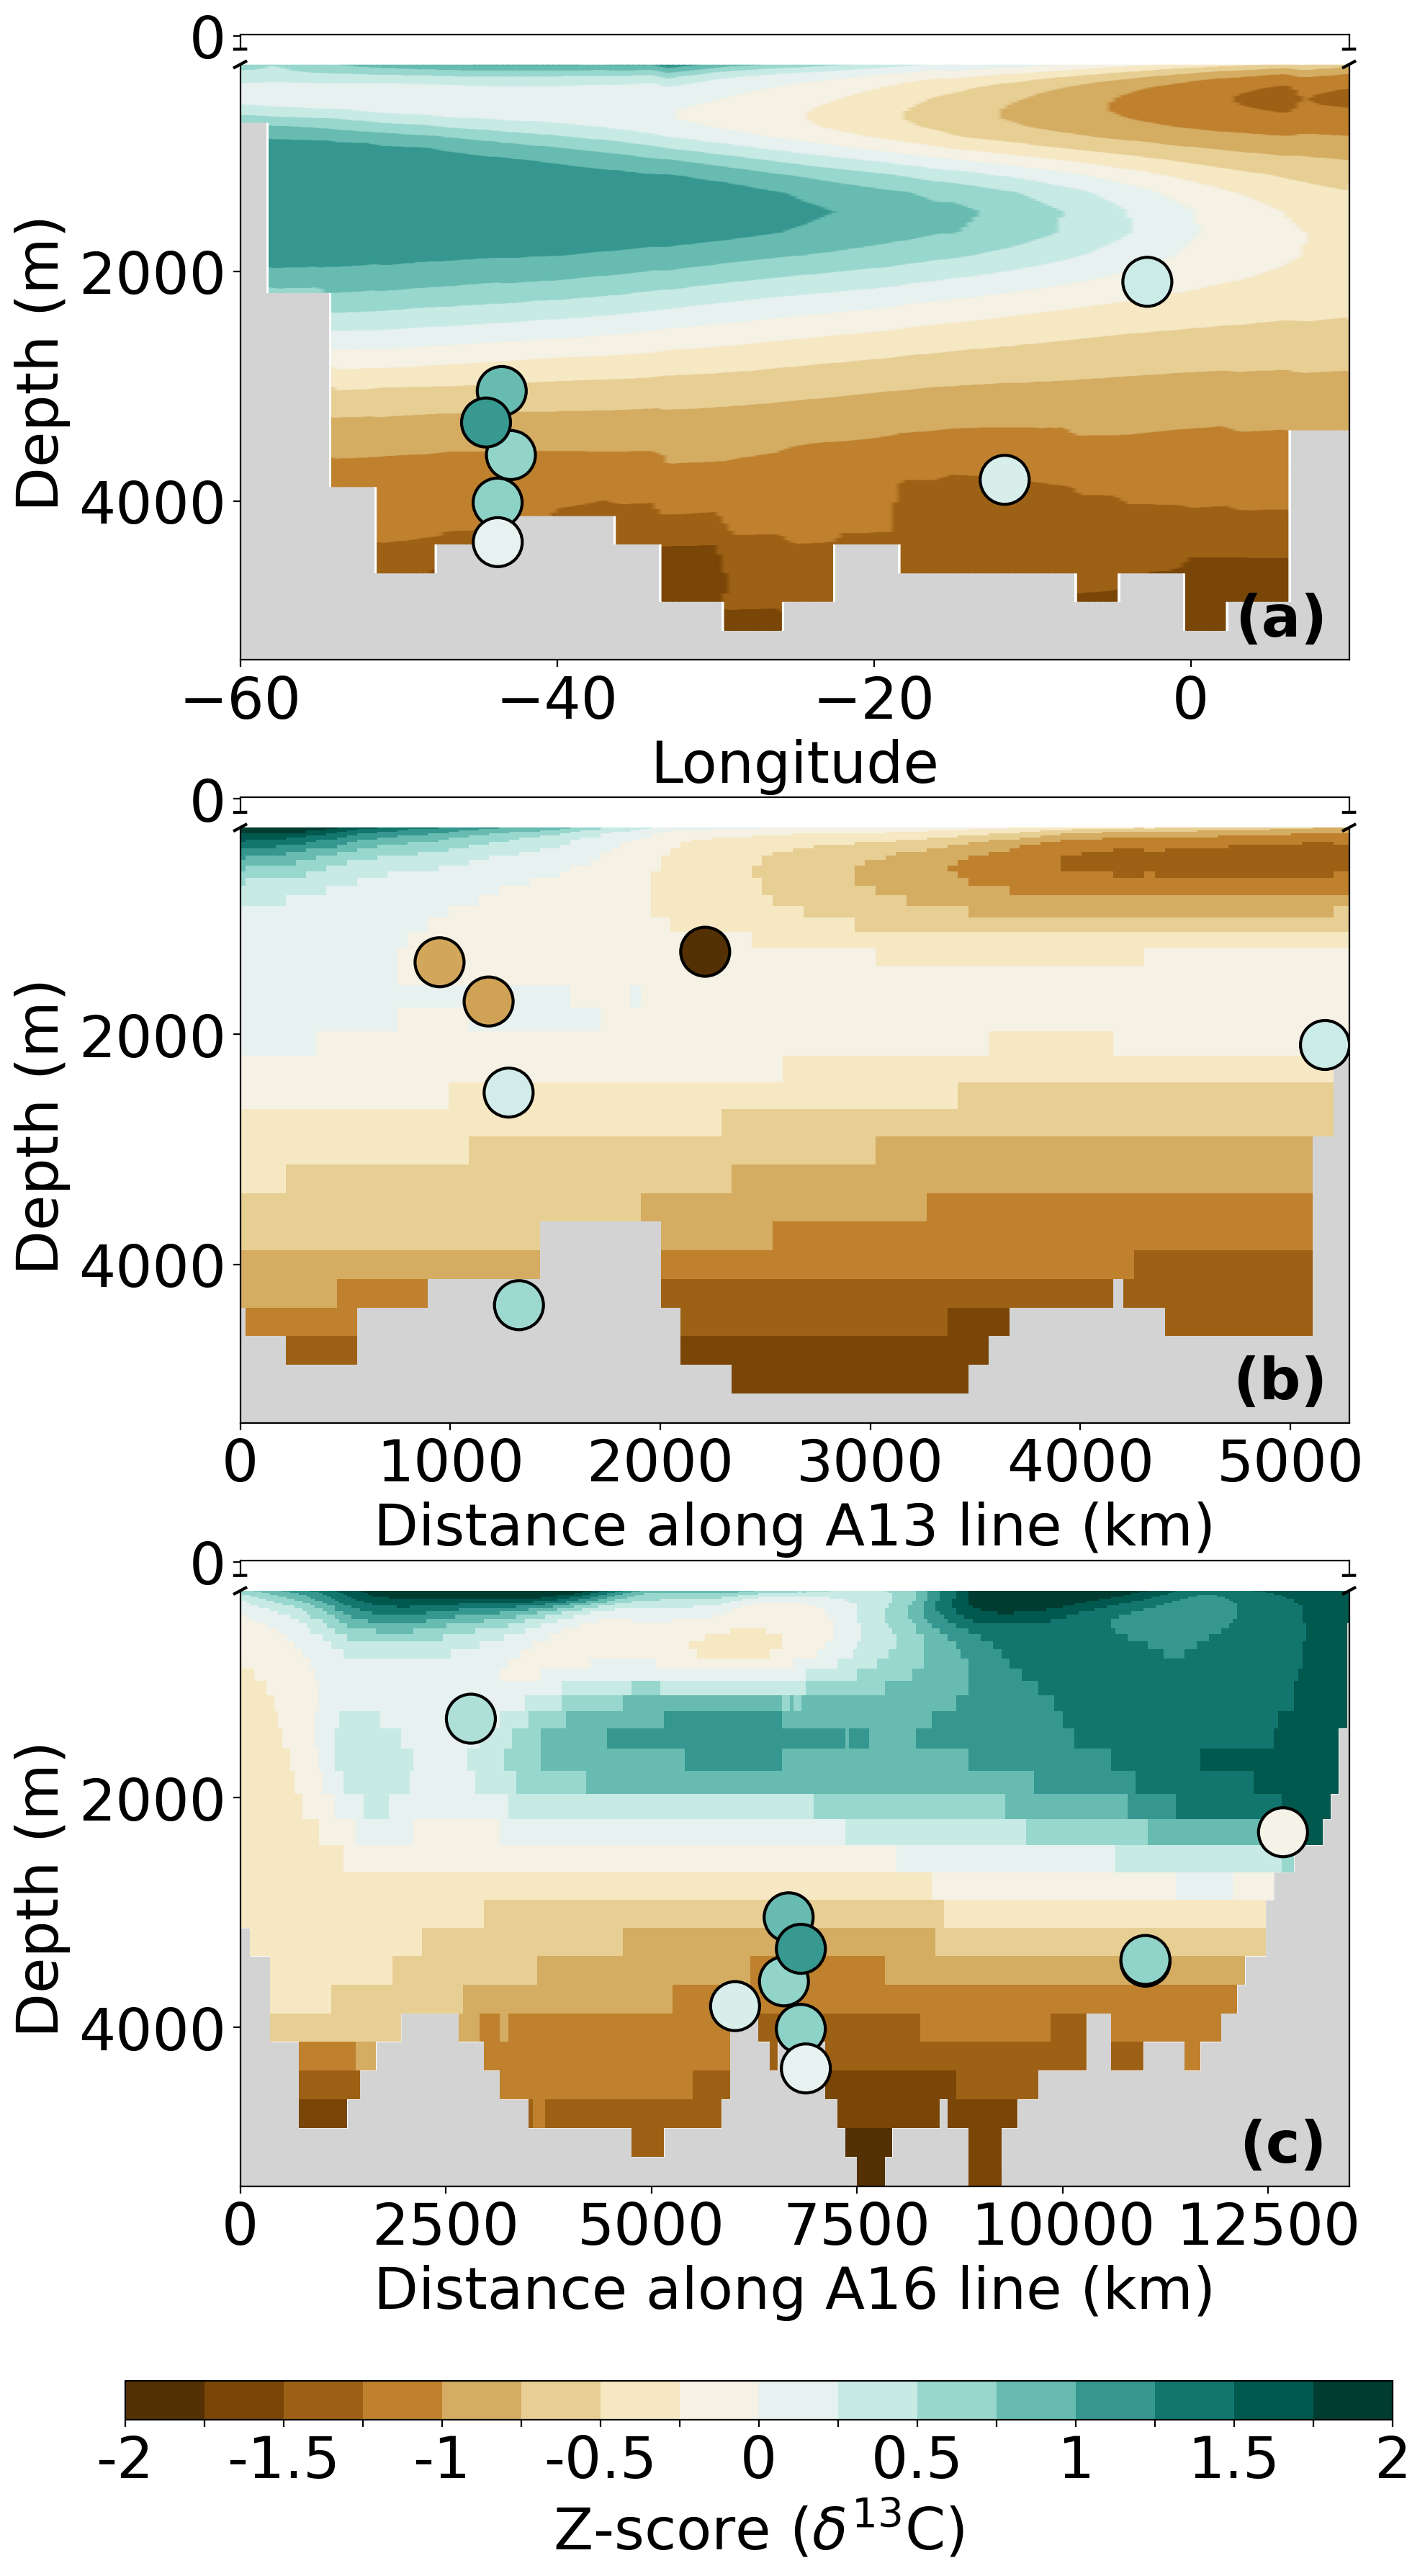

In [2]:

import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update(mpl.rcParamsDefault)
plt.rcdefaults()

mpl.rcParams.update({
    "font.size": 29,
    "axes.labelsize": 29,
    "xtick.labelsize": 29,
    "ytick.labelsize": 29,
})

# Transect geometry (d13C.ipynb) 
A13_line_lon = [10, 10, 9, 5, 5, -1]
A13_line_lat = [-40, -30, -25.3, -20, -5, 4.5]

A16_line_lon = [-36, -25, -25, -29, -29, -20, -20]
A16_line_lat = [-54, -35, 0, 11, 20, 36.5, 63.2]

box_lat_min, box_lat_max = -10.5, 10.5
box_lon_min, box_lon_max = -60, 10

color_bins = [-2, -1.75, -1.5, -1.25, -1, -0.75, -0.5, -0.25, 0, 0.25, 0.5, 0.75, 1, 1.25, 1.5, 1.75, 2]
num_colors = len(color_bins) - 1
colors = plt.cm.BrBG(np.linspace(0, 1, num_colors))
cmap = mcolors.ListedColormap(colors)
norm = mcolors.BoundaryNorm(boundaries=color_bins, ncolors=num_colors)

_ref_d13c, _ref_lat, _ref_depth = latdepthplot(
    cesm122_Plio_lat, cesm122_Plio_lon, cesm122_Plio_depth, cesm122_Plio_d13C, normalise=False,
)
ref_mean = np.nanmean(_ref_d13c)
ref_std = np.nanstd(_ref_d13c)

scatter_values = PLIOMIP2_d13C_comparison_table["PLIOMIP2 d13C"]
scatter_mean = np.nanmean(scatter_values)
scatter_std = np.nanstd(scatter_values)
scatter_norm = (scatter_values - scatter_mean) / scatter_std

points_df = PLIOMIP2_d13C_comparison_table.copy()
points_df = points_df[points_df["Site name"].astype(str).str.lower() != "average"].copy()
for column in ["Longitude", "Latitude", "Water depth (m)", "PLIOMIP2 d13C"]:
    points_df[column] = pd.to_numeric(points_df[column], errors="coerce")
points_df = points_df.dropna(subset=["Longitude", "Latitude", "Water depth (m)", "PLIOMIP2 d13C"]).copy()
points_df["Longitude_wrapped"] = ((points_df["Longitude"] + 180) % 360) - 180
points_df["scatter_norm"] = scatter_norm.loc[points_df.index]

equator_array, equator_lon, equator_depth = equatorplot(
    cesm122_Plio_lat, cesm122_Plio_lon, cesm122_Plio_depth, cesm122_Plio_d13C,
    latrange=[box_lat_min, box_lat_max],
    trimtop=True, normalise=False, top=200,
    mask=None, mask_lat=None, mask_lon=None,
)
equator_array = (equator_array - ref_mean) / ref_std

A13_sec = extract_transect_section_lon_band_mean(
    cesm122_Plio_d13C, cesm122_Plio_lat, cesm122_Plio_lon, cesm122_Plio_depth,
    A13_line_lon, A13_line_lat, spacing_km=50, mesh=False,
)
A16_sec = extract_transect_section_lon_band_mean(
    cesm122_Plio_d13C, cesm122_Plio_lat, cesm122_Plio_lon, cesm122_Plio_depth,
    A16_line_lon, A16_line_lat, spacing_km=50, mesh=False,
)

A13_data = ma.masked_invalid(A13_sec["section"])
A16_data = ma.masked_invalid(A16_sec["section"])
A13_data[A13_sec["depth"] < 200, :] = np.ma.masked
A16_data[A16_sec["depth"] < 200, :] = np.ma.masked

A13_data = (A13_data - ref_mean) / ref_std

A16_data = (A16_data - ref_mean) / ref_std

equator_points = points_df[
    points_df["Latitude"].between(box_lat_min, box_lat_max)
    & points_df["Longitude_wrapped"].between(box_lon_min, box_lon_max)
    & points_df["Water depth (m)"].between(200, 5380)
].copy()

A13_points = project_points_to_transect(
    points_df, A13_line_lon, A13_line_lat, "PLIOMIP2 d13C", longitude_window_deg=10.0,
)
A13_points = A13_points[A13_points["depth_m"].between(200, 5380)].copy()
A13_points["scatter_norm"] = (
    pd.to_numeric(A13_points["value"], errors="coerce") - scatter_mean
) / scatter_std

A16_points = project_points_to_transect(
    points_df, A16_line_lon, A16_line_lat, "PLIOMIP2 d13C", longitude_window_deg=10.0,
)
A16_points = A16_points[A16_points["depth_m"].between(200, 5380)].copy()
A16_points["scatter_norm"] = (
    pd.to_numeric(A16_points["value"], errors="coerce") - scatter_mean
) / scatter_std

panels = [
    {
        "data": equator_array,
        "x": equator_lon,
        "depth": equator_depth,
        "xlim": (box_lon_min, box_lon_max),
        "xlabel": "Longitude",
        "shading": "gouraud",
        "scatter_x": equator_points["Longitude_wrapped"],
        "scatter_y": equator_points["Water depth (m)"],
        "scatter_c": equator_points["scatter_norm"],
        "label": "(a)",
    },
    {
        "data": A13_data,
        "x": np.asarray(A13_sec["distance_km"], dtype=float),
        "depth": A13_sec["depth"],
        "xlim": (0, np.nanmax(A13_sec["distance_km"])),
        "xlabel": "Distance along A13 line (km)",
        "shading": "auto",
        "scatter_x": A13_points["distance_km"],
        "scatter_y": A13_points["depth_m"],
        "scatter_c": A13_points["scatter_norm"],
        "label": "(b)",
    },
    {
        "data": A16_data,
        "x": np.asarray(A16_sec["distance_km"], dtype=float),
        "depth": A16_sec["depth"],
        "xlim": (0, np.nanmax(A16_sec["distance_km"])),
        "xlabel": "Distance along A16 line (km)",
        "shading": "auto",
        "scatter_x": A16_points["distance_km"],
        "scatter_y": A16_points["depth_m"],
        "scatter_c": A16_points["scatter_norm"],
        "label": "(c)",
    },
]

fig = plt.figure(figsize=(10, 18), dpi=200)
outer_grid = fig.add_gridspec(
    3, 1, hspace=0.22, left=0.18, right=0.95, top=0.98, bottom=0.15,
)
pc_for_cbar = None

for row, panel in enumerate(panels):
    inner_grid = outer_grid[row, 0].subgridspec(2, 1, height_ratios=[1, 40], hspace=0.05)
    ax1 = fig.add_subplot(inner_grid[0, 0])
    ax2 = fig.add_subplot(inner_grid[1, 0], sharex=ax1)

    shade_below_bathymetry(ax1, panel["x"], panel["depth"], panel["data"])
    ax1.pcolormesh(
        panel["x"], panel["depth"], panel["data"],
        cmap=cmap, norm=norm, shading=panel["shading"],
    )
    ax1.set_ylim(-1, 10)
    ax1.set_xlim(panel["xlim"])
    ax1.set_yticks([0])
    ax1.tick_params(bottom=False, labelbottom=False)

    shade_below_bathymetry(ax2, panel["x"], panel["depth"], panel["data"])
    pc_for_cbar = ax2.pcolormesh(
        panel["x"], panel["depth"], panel["data"],
        cmap=cmap, norm=norm, shading=panel["shading"],
    )
    ax2.set_ylim(200, 5380)
    ax2.set_xlim(panel["xlim"])
    ax2.set_xlabel(panel["xlabel"])
    ax2.set_ylabel("Depth (m)")

    ax1.invert_yaxis()
    ax2.invert_yaxis()
    ax1.spines["bottom"].set_visible(False)
    ax2.spines["top"].set_visible(False)

    if not panel["scatter_x"].empty:
        ax2.scatter(
            panel["scatter_x"],
            panel["scatter_y"],
            c=panel["scatter_c"],
            cmap="BrBG",
            s=600,
            vmin=-2,
            vmax=2,
            marker="o",
            edgecolors="black",
            linewidths=1.5,
        )

    d = 0.005
    kwargs = dict(transform=ax1.transAxes, color="k", clip_on=False)
    ax1.plot((-d, +d), (-d, +d), **kwargs)
    ax1.plot((1 - d, 1 + d), (-d, +d), **kwargs)
    kwargs.update(transform=ax2.transAxes)
    ax2.plot((-d, +d), (1 - d, 1 + d), **kwargs)
    ax2.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)

    ax2.text(
        0.98, 0.02, panel["label"],
        transform=ax2.transAxes,
        ha="right", va="bottom",
        fontsize=29, fontweight="bold",
        zorder=20,
    )

cbar_ax = fig.add_axes([0.10, 0.06, 0.88, 0.015])

# Determine which ticks to label (skip .25 and .75 steps)
colorbar_ticklabels = []
for v in color_bins:
    # Label only if the value is an integer or half-integer (e.g. -2, -1.5, -1, ..., 1.5, 2)
    if (v * 4) % 1 == 0 and ((v * 2) % 1 == 0):  # e.g. -2, -1.5, -1, ... 1.0, 1.5, 2.0
        colorbar_ticklabels.append(f"{v:g}")
    else:
        colorbar_ticklabels.append("")

cbar = plt.colorbar(
    pc_for_cbar, cax=cbar_ax, orientation="horizontal",
    boundaries=color_bins, ticks=color_bins,
    format="",  # no automatic formatting
)
cbar_ax.set_xticklabels(colorbar_ticklabels)
cbar.set_label(r"Z-score ($\delta^{13}\mathrm{C}$)")

fig.savefig(FIG_DIR / "d13C_transects.png", dpi=300, bbox_inches="tight")
plt.show()
